<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/Task_5_Analytics_Report_%26_Executive_Insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seed for reproducibility
np.random.seed(2026)
n_samples = 1000

# Synthetic Enterprise Telemetry & Churn Analytics Dataset
data = {
    'tenant_id': [f"TNT_{i:04d}" for i in range(1, n_samples + 1)],
    'monthly_recurring_revenue': np.round(np.random.lognormal(mean=5.5, sigma=0.8, size=n_samples), 2),
    'api_calls_per_month': np.random.randint(500, 50000, size=n_samples),
    'support_tickets_raised': np.random.poisson(lam=2.5, size=n_samples),
    'customer_health_index': np.round(np.random.uniform(15.0, 99.0, size=n_samples), 1),
    'tier': np.random.choice(['Standard', 'Professional', 'Enterprise'], size=n_samples, p=[0.5, 0.35, 0.15])
}

df_analytics = pd.DataFrame(data)

# Calculate Derived Metric: Usage-to-Cost Efficiency Ratio
df_analytics['api_call_cost_ratio'] = df_analytics['api_calls_per_month'] / df_analytics['monthly_recurring_revenue']

# Executive Summary Metrics Calculation
total_mrr = df_analytics['monthly_recurring_revenue'].sum()
avg_health = df_analytics['customer_health_index'].mean()
tier_mrr = df_analytics.groupby('tier')['monthly_recurring_revenue'].agg(['count', 'sum', 'mean']).round(2)

print("=== EXECUTIVE TELEMETRY SUMMARY ===")
print(f"Total Platform MRR: ${total_mrr:,.2f}")
print(f"Global Average Health Index: {avg_health:.2f} / 100")
print("\n--- Revenue Breakdown by Service Tier ---")
print(tier_mrr)

=== EXECUTIVE TELEMETRY SUMMARY ===
Total Platform MRR: $363,073.25
Global Average Health Index: 56.73 / 100

--- Revenue Breakdown by Service Tier ---
              count        sum    mean
tier                                  
Enterprise      146   48851.96  334.60
Professional    357  135049.36  378.29
Standard        497  179171.93  360.51


In [2]:
# Identify High-Risk Accounts (Health Score < 40 & Tickets > 3)
df_analytics['risk_category'] = np.where(
    (df_analytics['customer_health_index'] < 40) & (df_analytics['support_tickets_raised'] > 3),
    'At-Risk Cohort',
    'Healthy Cohort'
)

# Cross-tabulation of Risk across Tiers
risk_cross_tab = pd.crosstab(df_analytics['tier'], df_analytics['risk_category'], margins=True)

# Risk Exposure Valuation
at_risk_mrr = df_analytics[df_analytics['risk_category'] == 'At-Risk Cohort']['monthly_recurring_revenue'].sum()
risk_pct = (at_risk_mrr / total_mrr) * 100

print("=== COHORT RISK EXPOSURE AUDIT ===")
print(f"Total MRR Exposed to At-Risk Cohort: ${at_risk_mrr:,.2f} ({risk_pct:.2f}% of total platform revenue)")
print("\n--- Tier vs. Risk Exposure Breakdown ---")
print(risk_cross_tab)

=== COHORT RISK EXPOSURE AUDIT ===
Total MRR Exposed to At-Risk Cohort: $28,655.02 (7.89% of total platform revenue)

--- Tier vs. Risk Exposure Breakdown ---
risk_category  At-Risk Cohort  Healthy Cohort   All
tier                                               
Enterprise                 14             132   146
Professional               23             334   357
Standard                   45             452   497
All                        82             918  1000


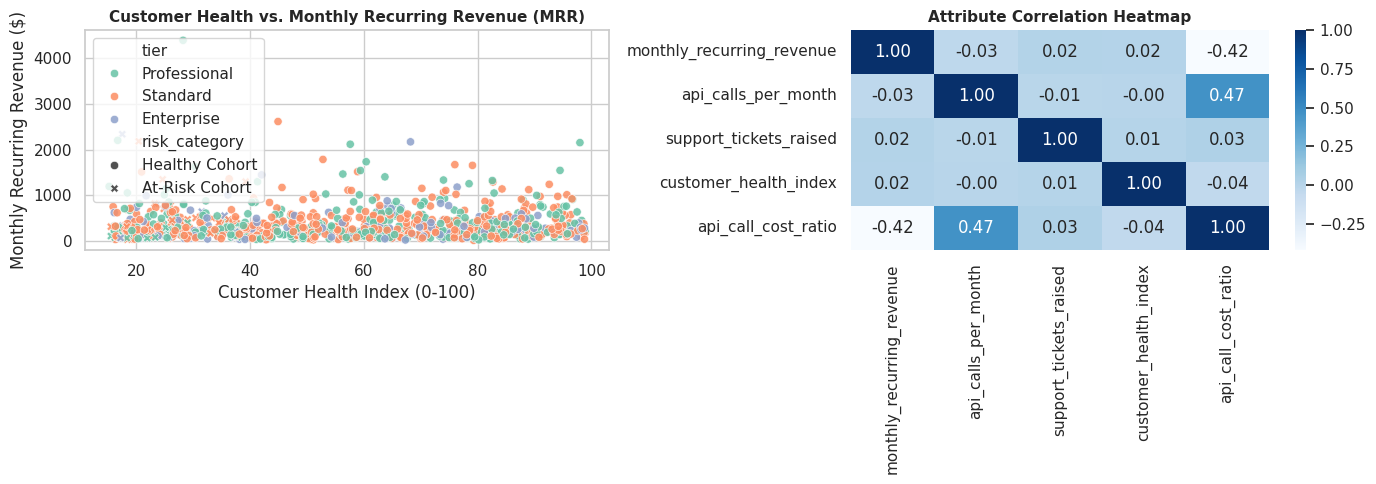

--- Telemetry Correlation Coefficients ---
customer_health_index        1.000000
monthly_recurring_revenue    0.016073
support_tickets_raised       0.008813
api_calls_per_month         -0.004398
api_call_cost_ratio         -0.040595
Name: customer_health_index, dtype: float64


In [3]:
# Visualization Suite Setup
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Revenue vs Health Index by Tier
sns.scatterplot(
    ax=axes[0], data=df_analytics, x='customer_health_index', y='monthly_recurring_revenue',
    hue='tier', style='risk_category', palette='Set2', alpha=0.85
)
axes[0].set_title("Customer Health vs. Monthly Recurring Revenue (MRR)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Customer Health Index (0-100)")
axes[0].set_ylabel("Monthly Recurring Revenue ($)")

# Plot 2: Correlation Heatmap of Telemetry Attributes
numeric_cols = df_analytics.select_dtypes(include=[np.number])
sns.heatmap(ax=axes[1], data=numeric_cols.corr(), annot=True, fmt=".2f", cmap="Blues", cbar=True)
axes[1].set_title("Attribute Correlation Heatmap", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("--- Telemetry Correlation Coefficients ---")
print(numeric_cols.corr()['customer_health_index'].sort_values(ascending=False))